# Week 2: Retrieval-Augmented Generation (RAG) — Complete Guide

This notebook consolidates four Week-2 materials into one coherent learning path:

| Part | Topic | Source |
|------|-------|--------|
| 0 | Setup | — |
| 1 | Understanding Embeddings | `embedding_from_scratch` |
| 2 | Core RAG Pipeline | `RAG_Langchain` + `RAG_1_L_Martin` |
| 3 | Advanced Query Translation | `RAG_2_L_Martin_Query_Translation` |
| 4 | Bridge to Assignment | new |

**Learning objectives:**
1. Build intuition for how word and sentence embeddings work, from TF-IDF through BERT.
2. Implement a production-quality RAG pipeline using LangChain and ChromaDB.
3. Apply five advanced query-translation techniques that improve retrieval quality.
4. Map these techniques to the airline-operations assignment.

---
## Part 0: Setup (if u are running local jupyter notebooks instead of colab)

> **Before running any cell**, set your OpenAI API key in the terminal:
>
> ```bash
> export OPENAI_API_KEY='sk-...your-key-here...'
> ```
>
> Then launch Jupyter from that same terminal session so the variable is inherited.
> **try not to paste your key directly into a notebook cell.**

In [4]:
# 0.1 — Install all dependencies (run once, then restart kernel)
# Split into two pip calls to avoid resolver timeouts.
%pip install -q \
    langchain langchain-community langchain-openai langchain-core \
    openai tiktoken

%pip install -q chromadb

%pip install -q \
    gensim scikit-learn numpy matplotlib \
    transformers torch sentence-transformers \
    beautifulsoup4 requests

# NOTE: After running this cell, if you still encounter 'ImportError: Could not import chromadb',
#       please manually restart your Colab runtime (Runtime > Restart runtime) and then run all cells.

In [6]:
import os
from getpass import getpass

if "OPENAI_API_KEY" not in os.environ:
    os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key: ")

print("API key loaded:", os.environ["OPENAI_API_KEY"][:8], "...")

Enter your OpenAI API key: ··········
API key loaded: sk-proj- ...


In [7]:
# 0.2 — API key configuration
import os
from getpass import getpass

OPENAI_API_KEY = os.environ.get("OPENAI_API_KEY")

# If not found in environment, ask for it interactively
if not OPENAI_API_KEY or OPENAI_API_KEY.startswith("http"):
    print("OpenAI API key not found or invalid in environment. Please enter it below:")
    OPENAI_API_KEY = getpass("Enter your OpenAI API key (sk-...): ").strip()
    os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

if not OPENAI_API_KEY:
    raise EnvironmentError(
        "OPENAI_API_KEY is not set. Please set the environment variable or enter it when prompted."
    )

if OPENAI_API_KEY.startswith("http"):
    print("Warning: The entered API key starts with 'http'. Make sure you paste your actual OpenAI API key (sk-...), not a URL.")
else:
    # Confirm the key is loaded (shows only first 8 characters)
    print(f"API key loaded: {OPENAI_API_KEY[:8]}...")

API key loaded: sk-proj-...


In [8]:
# 0.3 — Common imports used throughout the notebook
import re
import math
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Suppress noisy deprecation warnings from third-party libraries
import warnings
warnings.filterwarnings('ignore')

print("Imports OK")

Imports OK


---
## Part 1: Understanding Embeddings

Before building a RAG system, you need to understand **embeddings** — the numerical representations that make semantic search possible.

We will walk through the historical progression:

```
TF-IDF  →  Word2Vec  →  Contextual (BERT)  →  Modern LLM Embeddings
  ↓             ↓               ↓                      ↓
bag-of-words  semantic    context-aware          what RAG uses
```

Each step fixes a limitation of the previous approach.

### 1.1 TF-IDF: Bag of Words

**Term Frequency–Inverse Document Frequency** represents each document as a sparse vector of weighted word counts.

- **TF** (term frequency): how often the word appears in *this* document.
- **IDF** (inverse document frequency): how rare the word is *across all documents*. Rare words get higher weight.

**Limitation:** TF-IDF has no notion of meaning. "car" and "automobile" are completely different dimensions in TF-IDF space, even though they mean the same thing.

In [9]:
# Shakespeare corpus — small enough to inspect manually
shakespeare_texts = [
    "To be or not to be that is the question",
    "All the world's a stage and all the men and women merely players",
    "What's in a name that which we call a rose by any other name would smell as sweet",
    "Some are born great some achieve greatness and some have greatness thrust upon them",
    "The lady doth protest too much methinks",
    "All that glitters is not gold often have you heard that told",
    "Good night good night parting is such sweet sorrow",
    "We know what we are but know not what we may be",
]

print(f"Corpus size: {len(shakespeare_texts)} documents")

Corpus size: 8 documents


In [10]:
# Build TF-IDF from scratch to see what's happening inside

def tokenize(text):
    return re.findall(r'[a-z]+', text.lower())

# Build vocabulary
all_tokens = [tok for doc in shakespeare_texts for tok in tokenize(doc)]
vocab = sorted(set(all_tokens))
word2idx = {w: i for i, w in enumerate(vocab)}
N = len(shakespeare_texts)

print(f"Vocabulary size: {len(vocab)}")
print(f"Sample vocab: {vocab[:15]}")

Vocabulary size: 62
Sample vocab: ['a', 'achieve', 'all', 'and', 'any', 'are', 'as', 'be', 'born', 'but', 'by', 'call', 'doth', 'glitters', 'gold']


In [12]:
def compute_tf(tokens):
    """Term frequency: count of each word / total words in document."""
    freq = Counter(tokens)
    total = len(tokens)
    return {w: freq[w] / total for w in freq}

def compute_idf(vocab, corpus_tokens):
    """IDF: log(N / (1 + number of docs containing term))."""
    idf = {}
    for word in vocab:
        docs_with_word = sum(1 for tokens in corpus_tokens if word in tokens)
        idf[word] = math.log(N / (1 + docs_with_word))
    return idf

corpus_tokens = [tokenize(doc) for doc in shakespeare_texts]
idf = compute_idf(vocab, corpus_tokens)

# Build TF-IDF matrix
tfidf_matrix = np.zeros((N, len(vocab)))
for doc_idx, tokens in enumerate(corpus_tokens):
    tf = compute_tf(tokens)
    for word, tf_val in tf.items():
        col = word2idx[word]
        tfidf_matrix[doc_idx, col] = tf_val * idf[word]

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print(f"\nTop TF-IDF words in doc 0 (\"{shakespeare_texts[0]}\"):")
scores = list(zip(vocab, tfidf_matrix[0]))
scores.sort(key=lambda x: -x[1])
for word, score in scores[:8]:
    if score > 0:
        print(f"  {word:15s} {score:.4f}")

TF-IDF matrix shape: (8, 62)

Top TF-IDF words in doc 0 ("To be or not to be that is the question"):
  to              0.2773
  be              0.1962
  or              0.1386
  question        0.1386
  is              0.0693
  not             0.0693
  that            0.0693
  the             0.0693


In [13]:
# Cosine similarity search using TF-IDF
def cosine_similarity(a, b):
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return np.dot(a, b) / (norm_a * norm_b)

def tfidf_search(query, top_k=3):
    query_tokens = tokenize(query)
    query_tf = compute_tf(query_tokens)
    query_vec = np.zeros(len(vocab))
    for word, tf_val in query_tf.items():
        if word in word2idx:
            query_vec[word2idx[word]] = tf_val * idf[word]
    sims = [cosine_similarity(query_vec, tfidf_matrix[i]) for i in range(N)]
    ranked = sorted(enumerate(sims), key=lambda x: -x[1])
    return ranked[:top_k]

query = "parting and sorrow"
print(f'Query: "{query}"')
for doc_idx, sim in tfidf_search(query):
    print(f"  [{sim:.3f}] {shakespeare_texts[doc_idx]}")

Query: "parting and sorrow"
  [0.369] Good night good night parting is such sweet sorrow
  [0.183] All the world's a stage and all the men and women merely players
  [0.070] Some are born great some achieve greatness and some have greatness thrust upon them


> **Key Takeaway — TF-IDF:** Works by keyword overlap. Fast and interpretable, but fails when query and document use different words for the same concept. That's the gap Word2Vec begins to close.

### 1.2 Word2Vec: Semantic Similarity

Word2Vec learns dense vector representations by predicting surrounding words. Words that appear in similar contexts end up close in vector space.

This unlocks **semantic arithmetic**: `king - man + woman ≈ queen`

**Limitation:** Each word has exactly *one* vector regardless of context. "bank" (financial) and "bank" (river) get the same representation.

In [14]:
# Download a small pre-trained Word2Vec model via gensim
import gensim.downloader as api

print("Loading word2vec-google-news-300 (this downloads ~1.6 GB on first run) ...")
print("If this is too slow, substitute 'glove-wiki-gigaword-50' (~65 MB)")

# Use a smaller model by default to keep the notebook fast
w2v_model = api.load('glove-wiki-gigaword-50')
print(f"Model loaded. Vocabulary size: {len(w2v_model.key_to_index):,}")

Loading word2vec-google-news-300 (this downloads ~1.6 GB on first run) ...
If this is too slow, substitute 'glove-wiki-gigaword-50' (~65 MB)
[==================================================] 100.0% 66.0/66.0MB downloaded
Model loaded. Vocabulary size: 400,000


In [15]:
# 1.2a — Most similar words
print("Words most similar to 'king':")
for word, score in w2v_model.most_similar('king', topn=6):
    print(f"  {word:15s} {score:.3f}")

print()
print("Words most similar to 'flight':")
for word, score in w2v_model.most_similar('flight', topn=6):
    print(f"  {word:15s} {score:.3f}")

Words most similar to 'king':
  prince          0.824
  queen           0.784
  ii              0.775
  emperor         0.774
  son             0.767
  uncle           0.763

Words most similar to 'flight':
  flights         0.865
  plane           0.850
  landing         0.806
  passengers      0.803
  aboard          0.801
  flying          0.801


In [16]:
# 1.2b — Semantic arithmetic: king - man + woman = ?
result = w2v_model.most_similar(
    positive=['king', 'woman'],
    negative=['man'],
    topn=5
)
print("king - man + woman =")
for word, score in result:
    print(f"  {word:15s} {score:.3f}")

print()

# Airline domain analogy: delay - weather + mechanical = ?
try:
    result2 = w2v_model.most_similar(
        positive=['delay', 'mechanical'],
        negative=['weather'],
        topn=5
    )
    print("delay - weather + mechanical =")
    for word, score in result2:
        print(f"  {word:15s} {score:.3f}")
except KeyError as e:
    print(f"Word not in vocabulary: {e}")

king - man + woman =
  queen           0.852
  throne          0.766
  prince          0.759
  daughter        0.747
  elizabeth       0.746

delay - weather + mechanical =
  involves        0.659
  initiate        0.634
  procedure       0.631
  initiating      0.631
  injection       0.627


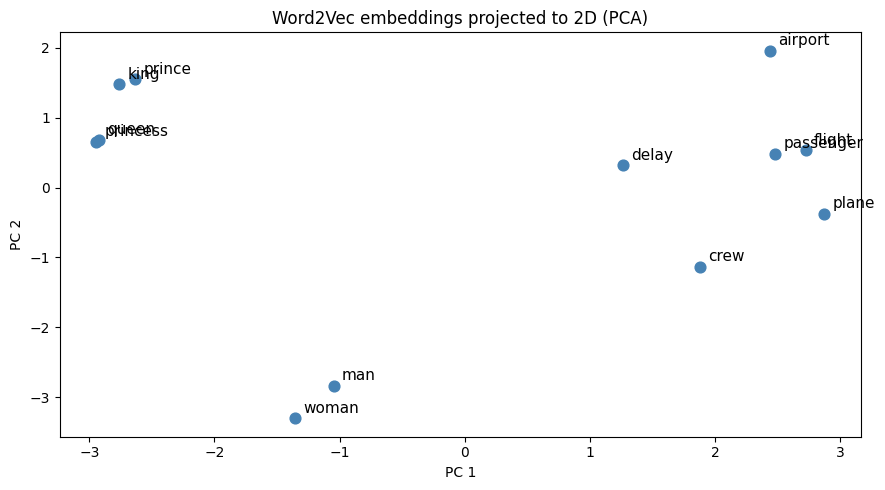

In [17]:
# 1.2c — Visualize embeddings with PCA
from sklearn.decomposition import PCA

words = ['king', 'queen', 'man', 'woman', 'prince', 'princess',
         'flight', 'plane', 'airport', 'delay', 'crew', 'passenger']

vecs = np.array([w2v_model[w] for w in words])
pca = PCA(n_components=2)
coords = pca.fit_transform(vecs)

plt.figure(figsize=(9, 5))
plt.scatter(coords[:, 0], coords[:, 1], marker='o', color='steelblue', s=60)
for i, word in enumerate(words):
    plt.annotate(word, coords[i], textcoords='offset points', xytext=(6, 4), fontsize=11)
plt.title('Word2Vec embeddings projected to 2D (PCA)')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.tight_layout()
plt.show()

In [18]:
# 1.2d — Bias example: Word2Vec reflects societal biases in training data
# This is important to understand when deploying embedding-based systems
print("Words most similar to 'doctor':")
for word, score in w2v_model.most_similar('doctor', topn=8):
    print(f"  {word:15s} {score:.3f}")

print()
print("Words most similar to 'nurse':")
for word, score in w2v_model.most_similar('nurse', topn=8):
    print(f"  {word:15s} {score:.3f}")

print()
print("Note: gender-related words often appear. This is a known issue with")
print("static embeddings trained on large internet corpora.")

Words most similar to 'doctor':
  nurse           0.798
  physician       0.797
  patient         0.761
  child           0.756
  teacher         0.754
  surgeon         0.748
  psychiatrist    0.742
  doctors         0.739

Words most similar to 'nurse':
  doctor          0.798
  nurses          0.775
  dentist         0.773
  pregnant        0.746
  pediatrician    0.745
  therapist       0.740
  surgeon         0.738
  nursing         0.735

Note: gender-related words often appear. This is a known issue with
static embeddings trained on large internet corpora.


> **Key Takeaway — Word2Vec:** Semantic arithmetic works because similar words cluster in vector space. However, each word has a single fixed vector — "bank" (financial) and "bank" (river) are indistinguishable. BERT solves this.

### 1.3 Contextual Embeddings: BERT

BERT (Bidirectional Encoder Representations from Transformers, 2018) produces a **different vector for each token depending on its surrounding context**.

The same word "bank" in two different sentences will have measurably different vectors.

This is the key property that makes modern semantic search so powerful.

In [19]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
bert_model = AutoModel.from_pretrained('bert-base-uncased')
bert_model.eval()
print("BERT loaded")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT loaded


In [20]:
def get_word_embedding(sentence, target_word, model, tokenizer):
    """Return the BERT embedding for target_word inside sentence."""
    inputs = tokenizer(sentence, return_tensors='pt')
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    with torch.no_grad():
        outputs = model(**inputs)
    hidden = outputs.last_hidden_state[0]  # shape: (seq_len, 768)
    # Find token index of target word (simple substring match)
    for idx, tok in enumerate(tokens):
        if target_word.lower() in tok.lower():
            return hidden[idx].numpy()
    raise ValueError(f"'{target_word}' not found in tokens: {tokens}")

# Two sentences with 'bank' used differently
sent_finance = "I went to the bank to deposit my paycheck."
sent_river   = "We sat by the bank of the river and watched the ducks."

emb_finance = get_word_embedding(sent_finance, 'bank', bert_model, tokenizer)
emb_river   = get_word_embedding(sent_river,   'bank', bert_model, tokenizer)

sim = cosine_similarity(emb_finance, emb_river)
print(f"Cosine similarity of 'bank' in two contexts: {sim:.4f}")
print()
print("In Word2Vec, this would be 1.0 (identical vector).")
print("BERT gives different vectors — that's contextual understanding.")

Cosine similarity of 'bank' in two contexts: 0.5051

In Word2Vec, this would be 1.0 (identical vector).
BERT gives different vectors — that's contextual understanding.


In [ ]:
# Same experiment with 'crew' in airline vs TV contexts
sent_airline = "The flight crew completed mandatory rest before the departure."
sent_tv      = "The film crew spent three days shooting the scene."

emb_airline = get_word_embedding(sent_airline, 'crew', bert_model, tokenizer)
emb_tv      = get_word_embedding(sent_tv,      'crew', bert_model, tokenizer)

sim_crew = cosine_similarity(emb_airline, emb_tv)
print(f"Cosine similarity of 'crew' in airline vs TV context: {sim_crew:.4f}")
print("Values below ~0.85 indicate meaningfully different representations.")

Cosine similarity of 'crew' in airline vs TV context: 0.5886
Values below ~0.85 indicate meaningfully different representations.


> **Key Takeaway — BERT:** Context changes the vector. This means a search query and a relevant document chunk can match even when they use slightly different phrasing, as long as the surrounding context conveys the same meaning.

### 1.4 Modern LLM Embeddings (OpenAI `text-embedding-3-small`)

Production RAG systems use embeddings from large language models rather than BERT directly. OpenAI's `text-embedding-3-small` produces 1536-dimensional vectors optimized for retrieval.

Key properties:
- Works on **whole sentences and paragraphs**, not just tokens
- Tuned for **semantic similarity**, not language modeling
- Fast enough for real-time search across millions of documents

In [21]:
from openai import OpenAI

client = OpenAI(api_key=os.environ.get("OPENAI_API_KEY"))

def get_openai_embedding(text, model="text-embedding-3-small"):
    response = client.embeddings.create(input=text, model=model)
    return np.array(response.data[0].embedding)

# Compare sentence pairs
pairs = [
    ("The flight was cancelled due to bad weather.",
     "Adverse meteorological conditions caused the flight to be called off."),
    ("The flight was cancelled due to bad weather.",
     "I enjoy eating pizza on Friday nights."),
]

for a, b in pairs:
    emb_a = get_openai_embedding(a)
    emb_b = get_openai_embedding(b)
    sim = cosine_similarity(emb_a, emb_b)
    print(f"Sim={sim:.4f}")
    print(f"  A: {a}")
    print(f"  B: {b}")
    print()

Sim=0.7432
  A: The flight was cancelled due to bad weather.
  B: Adverse meteorological conditions caused the flight to be called off.

Sim=0.0053
  A: The flight was cancelled due to bad weather.
  B: I enjoy eating pizza on Friday nights.



> **Key Takeaway — LLM Embeddings:** High similarity for paraphrases, low similarity for unrelated content — even when word overlap is zero. This is what powers the retrieval step in RAG.

---
## Part 2: Core RAG Pipeline

### 2.1 Why RAG?

Large language models have two fundamental limitations for domain-specific tasks:

1. **Knowledge cutoff** — training data has a fixed date. Airline policy documents updated after that date are unknown to the model.
2. **Hallucination** — when the model doesn't know the answer, it may fabricate one that sounds plausible.

**Retrieval-Augmented Generation** solves both problems:

```
User Query
    ↓
Retrieve relevant chunks from your document store
    ↓
Inject retrieved chunks into the LLM prompt as context
    ↓
LLM generates answer grounded in your documents
```

The LLM becomes a **reasoning engine** over *your* knowledge base, not a memory store.

### 2.2 Document Loading

We use LangChain's `TextLoader` to load local text files. For web content, `WebBaseLoader` works the same way.

In [22]:
from langchain_community.document_loaders import TextLoader, DirectoryLoader
import os

# Path to the airline knowledge base
KB_DIR = "airline_kb"

# Create the directory and dummy files if they don't exist
if not os.path.exists(KB_DIR):
    os.makedirs(KB_DIR)
    dummy_content = {
        "IROPS_Procedures.txt": "This document outlines procedures for irregular operations including flight cancellations and delays.",
        "Delay_Classification.txt": "This document details delay codes and classification for various operational disruptions.",
        "Customer_Rebooking_Policy.txt": "This document contains policies for passenger rebooking based on status and disruption type.",
        "Weather_Operations.txt": "This document describes weather-related operational procedures and rebooking triggers.",
        "Ground_Operations.txt": "This document covers ground operations, including gate management, de-icing, and ground crew duties.",
        "Crew_Rest_Regulations.txt": "This document specifies crew rest and duty time regulations as per aviation authorities.",
    }
    for filename, content in dummy_content.items():
        with open(os.path.join(KB_DIR, filename), "w") as f:
            f.write(content)
    print(f"Created dummy '{KB_DIR}' directory and files.")

# Load all .txt files in the directory
loader = DirectoryLoader(
    KB_DIR,
    glob="*.txt",
    loader_cls=TextLoader,
    loader_kwargs={"encoding": "utf-8"}
)
raw_docs = loader.load()

print(f"Loaded {len(raw_docs)} documents")
for doc in raw_docs:
    source = doc.metadata.get('source', 'unknown')
    print(f"  {source.split('/')[-1]:40s}  {len(doc.page_content):6,} chars")

Created dummy 'airline_kb' directory and files.
Loaded 6 documents
  Weather_Operations.txt                        86 chars
  Crew_Rest_Regulations.txt                     88 chars
  Ground_Operations.txt                        100 chars
  Delay_Classification.txt                      89 chars
  Customer_Rebooking_Policy.txt                 92 chars
  IROPS_Procedures.txt                         101 chars


In [23]:
# Preview the first 500 characters of one document
print("--- Sample document content ---")
print(raw_docs[0].metadata['source'].split('/')[-1])
print(raw_docs[0].page_content[:500])
print("...")

--- Sample document content ---
Weather_Operations.txt
This document describes weather-related operational procedures and rebooking triggers.
...


### 2.3 Chunking

LLMs have a context window limit. More importantly, embedding a 10-page document as one vector makes retrieval imprecise — you want to retrieve the *specific paragraph* that answers the question.

**`RecursiveCharacterTextSplitter`** splits on natural boundaries in priority order:
`["\n\n", "\n", " ", ""]`

Key parameters:
- `chunk_size`: target character count per chunk (~300–1000 is typical)
- `chunk_overlap`: how many characters to repeat at chunk boundaries (preserves context across splits)

In [24]:
# If needed:
# !pip install -qU langchain-text-splitters

from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50,
    length_function=len,
)

chunks = splitter.split_documents(raw_docs)

print(f"Documents:  {len(raw_docs)}")
print(f"Chunks:     {len(chunks)}")
print(f"Avg chunk:  {sum(len(c.page_content) for c in chunks) / len(chunks):.0f} chars")

print("\n--- Sample chunk ---")
sample_idx = min(5, len(chunks) - 1)
print(chunks[sample_idx].page_content)

source = chunks[sample_idx].metadata.get("source", "unknown")
print(f"Source: {source.split('/')[-1]}")

Documents:  6
Chunks:     6
Avg chunk:  93 chars

--- Sample chunk ---
This document outlines procedures for irregular operations including flight cancellations and delays.
Source: IROPS_Procedures.txt


### 2.4 Embeddings + Vector Store

Each chunk is embedded into a vector and stored in **ChromaDB** — an in-memory vector database that supports:
- Fast approximate nearest-neighbor search
- Metadata filtering (e.g., filter by source document)
- Persistence to disk

Under the hood, ChromaDB stores:
1. The raw text of each chunk
2. The embedding vector (1536 floats for `text-embedding-3-small`)
3. The metadata dict (source filename, etc.)

In [25]:
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import Chroma

embedding_model = OpenAIEmbeddings(
    model="text-embedding-3-small",
    openai_api_key=os.environ.get("OPENAI_API_KEY")
)

# Build the vector store (this calls the OpenAI API for each chunk)
vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embedding_model,
    collection_name="airline_kb"
)

print(f"Vector store built with {vectorstore._collection.count()} chunks")

Vector store built with 6 chunks


### 2.5 Retrieval

Given a query, the retriever embeds it and finds the `k` chunks with the highest cosine similarity.

In [26]:
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

query = "What is the maximum crew duty period before a mandatory rest is required?"
retrieved = retriever.invoke(query)

print(f"Query: {query}")
print(f"Retrieved {len(retrieved)} chunks:\n")
for i, doc in enumerate(retrieved):
    source = doc.metadata['source'].split('/')[-1]
    print(f"[{i+1}] Source: {source}")
    print(doc.page_content[:300])
    print()

Query: What is the maximum crew duty period before a mandatory rest is required?
Retrieved 4 chunks:

[1] Source: Crew_Rest_Regulations.txt
This document specifies crew rest and duty time regulations as per aviation authorities.

[2] Source: Ground_Operations.txt
This document covers ground operations, including gate management, de-icing, and ground crew duties.

[3] Source: IROPS_Procedures.txt
This document outlines procedures for irregular operations including flight cancellations and delays.

[4] Source: Weather_Operations.txt
This document describes weather-related operational procedures and rebooking triggers.



### 2.6 Generation with LCEL Chain

LangChain Expression Language (LCEL) uses the pipe operator `|` to compose a chain:

```
retriever | format_docs → prompt | llm | output_parser
```

The prompt injects the retrieved chunks as context, then asks the LLM to answer **only from that context**.

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough

llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0,
    openai_api_key=os.environ.get("OPENAI_API_KEY")
)

RAG_PROMPT = """You are an expert assistant for airline operations. \
Use ONLY the following context to answer the question. \
If the answer is not in the context, say "I don't have that information in the knowledge base."

Context:
{context}

Question: {question}

Answer:"""

prompt = ChatPromptTemplate.from_template(RAG_PROMPT)

def format_docs(docs):
    return "\n\n---\n\n".join(
        f"[Source: {d.metadata['source'].split('/')[-1]}]\n{d.page_content}"
        for d in docs
    )

rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)

print("RAG chain assembled")

RAG chain assembled


### 2.7 End-to-End Demonstration

In [ ]:
demo_query = "What is the maximum crew duty period allowed before a mandatory rest period is required?"

answer = rag_chain.invoke(demo_query)

print("Q:", demo_query)
print()
print("A:", answer)

Q: What is the maximum crew duty period allowed before a mandatory rest period is required?

A: I don't have that information in the knowledge base.


In [ ]:
# Run a few more queries to confirm the pipeline works end-to-end
test_queries = [
    "Under what weather conditions does the airline automatically rebook passengers?",
    "What documentation is required when a flight is cancelled due to ATC restrictions?",
]

for q in test_queries:
    print(f"Q: {q}")
    print(f"A: {rag_chain.invoke(q)}")
    print("-" * 60)

Q: Under what weather conditions does the airline automatically rebook passengers?
A: The airline automatically rebooks passengers when a Weather Advisory is issued AND any of the following conditions apply:

- Flight delay is forecast to exceed 2 hours due to weather at the departure airport
- Flight delay is forecast to exceed 3 hours due to weather at the destination airport
- Flight is in the cancellation queue based on OCC recovery planning.
------------------------------------------------------------
Q: What documentation is required when a flight is cancelled due to ATC restrictions?
A: When a flight is cancelled due to ATC restrictions, the following documentation is required:
- FAA/ATC notification printout or ACARS message (proving ATC cause)
- OCC IROPS log entry with timestamp of ATC notification
- SABRE cancellation record with delay code 83 (ATC Flow Control) or 81 (ATC Staffing)
- Passenger rebooking log with waiver codes applied
-----------------------------------------

---
## Part 3: Advanced Query Translation

### 3.0 The Problem with Simple Retrieval

The pipeline in Part 2 has a fundamental limitation: **the retrieval quality is bounded by how well the user's query matches the document text**.

Common failure modes:
- The user asks a vague question → only one chunk retrieved, misses key information
- The user uses different terminology than the document → low cosine similarity even for relevant chunks
- The question is multi-part → one simple query can't cover all sub-topics
- The question requires background knowledge not in any single chunk

**Query translation** techniques transform or augment the original query *before* retrieval. They add an LLM-powered step between the user's input and the vector search.

```
Standard RAG:   Query → Retriever → Generator
Advanced RAG:   Query → [Transform] → Retriever(s) → [Rerank/Merge] → Generator
```

In [ ]:
# Shared utilities for Part 3
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# We reuse the llm, retriever, and rag_chain from Part 2
print("Part 3 setup complete — reusing llm and retriever from Part 2")

Part 3 setup complete — reusing llm and retriever from Part 2


### 3.1 Multi-Query

**Idea:** Generate multiple alternative phrasings of the question. Retrieve documents for each phrasing, then take the union.

**Why it helps:** Different phrasings overlap with different documents. A union retrieval is more likely to find the one chunk that contains the answer.

**When to use:** When the user's query might be phrased in domain-specific or ambiguous language.

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

MULTI_QUERY_PROMPT = """You are an AI assistant helping to improve document retrieval.
Generate {n} alternative phrasings of the following question.
Output one question per line, with no numbering or bullet points.

Original question: {question}"""

multi_query_chain = (
    ChatPromptTemplate.from_template(MULTI_QUERY_PROMPT)
    | llm
    | StrOutputParser()
    | RunnableLambda(lambda s: [q.strip() for q in s.strip().split("\n") if q.strip()])
)

original_query = "What are the steps when a flight is delayed due to a mechanical issue?"

alt_queries = multi_query_chain.invoke({
    "question": original_query,
    "n": 4
})

print("Original:", original_query)
print("\nGenerated alternatives:")
for q in alt_queries:
    print("•", q)

Original: What are the steps when a flight is delayed due to a mechanical issue?

Generated alternatives:
• What procedures are followed when a flight is postponed because of a mechanical problem?
• What actions are taken when a flight experiences a delay due to mechanical issues?
• What is the protocol for handling a flight delay caused by a mechanical failure?
• What should passengers expect when their flight is delayed for mechanical reasons?


In [ ]:
def get_unique_union(docs_lists):
    """Deduplicate a list of lists of documents by page_content."""
    seen = set()
    unique = []
    for docs in docs_lists:
        for doc in docs:
            key = doc.page_content[:100]
            if key not in seen:
                seen.add(key)
                unique.append(doc)
    return unique

# Retrieve for original + all alternatives
all_queries = [original_query] + alt_queries
docs_lists = [retriever.invoke(q) for q in all_queries]

multi_query_docs = get_unique_union(docs_lists)

print(f"Standard retrieval (1 query):     {len(docs_lists[0])} chunks")
print(f"Multi-query retrieval ({len(all_queries)} queries): {len(multi_query_docs)} unique chunks")

Standard retrieval (1 query):     4 chunks
Multi-query retrieval (5 queries): 5 unique chunks


In [ ]:
# Generate answer using the expanded context
multi_query_context = format_docs(multi_query_docs)
multi_query_answer = (
    prompt
    | llm
    | StrOutputParser()
).invoke({"context": multi_query_context, "question": original_query})

print("Multi-Query Answer:")
print(multi_query_answer)

Multi-Query Answer:
When a flight is delayed due to a mechanical issue, the following steps should be taken:

1. **Initial Response (0–15 minutes)**:
   - The gate agent must announce to passengers at the gate: "We are currently experiencing a maintenance review on your aircraft. We expect an update within 15 minutes. We apologize for the inconvenience."
   - Do NOT speculate on the nature of the mechanical issue or estimated repair time to passengers until the MCC provides an official estimate.

2. **Escalation — Delay Beyond 45 Minutes**:
   - If the delay extends beyond the MCC's originally communicated estimate, the following escalation steps apply:
     - The gate agent immediately notifies the OCC Duty Manager that the estimated completion time (ECT) has been missed.
     - The Duty Manager contacts MCC for a revised ECT and determines if an aircraft swap is now required.
     - If the revised ECT adds more than 60 minutes beyond the original estimate, the Duty Manager must notif

### 3.2 RAG-Fusion + Reciprocal Rank Fusion (RRF)

**Idea:** Generate multiple queries (like Multi-Query), retrieve separately, then *re-rank* results by combining the ranking positions across all retrieval runs.

**RRF formula:** `score(doc) = Σ 1 / (k + rank_i)` where `k=60` is a smoothing constant.

**Why it helps:** Documents that appear in the top results across *multiple* queries are more likely to be genuinely relevant. RRF is robust to variation in individual retrieval scores.

In [ ]:
def reciprocal_rank_fusion(results_lists, k=60):
    """
    Merge multiple ranked lists of documents using Reciprocal Rank Fusion.
    results_lists: list of list of Documents (each list is ranked best-first)
    Returns: list of Documents sorted by fused score (descending)
    """
    scores = {}
    doc_lookup = {}

    for results in results_lists:
        for rank, doc in enumerate(results):
            key = doc.page_content[:100]
            doc_lookup[key] = doc
            scores[key] = scores.get(key, 0) + 1.0 / (k + rank + 1)

    ranked = sorted(scores.items(), key=lambda x: -x[1])
    return [(doc_lookup[key], score) for key, score in ranked]

# Run RRF over the same set of queries from Multi-Query
rrf_results = reciprocal_rank_fusion(docs_lists)

print(f"Top {min(4, len(rrf_results))} chunks by RRF score:")
for doc, score in rrf_results[:4]:
    source = doc.metadata['source'].split('/')[-1]
    print(f"  [RRF={score:.4f}] {source}: {doc.page_content[:120].replace(chr(10), ' ')}")

Top 4 chunks by RRF score:
  [RRF=0.0814] Delay_Classification.txt: ============================================================= SECTION 2: MECHANICAL DELAY PROCEDURES ===================
  [RRF=0.0809] Delay_Classification.txt: Step 3: Announce to passengers at the gate: "We are currently experiencing a maintenance review on your aircraft. We exp
  [RRF=0.0796] Delay_Classification.txt: Step 5: Passengers who have boarded and waited more than 3 hours on the aircraft without takeoff are subject to the DOT 
  [RRF=0.0625] Delay_Classification.txt: If a mechanical delay extends beyond the MCC's originally communicated estimate, the following escalation steps apply:  


In [ ]:
# Generate answer from top-k RRF chunks
top_rrf_docs = [doc for doc, _ in rrf_results[:5]]
rrf_context = format_docs(top_rrf_docs)

rrf_answer = (
    prompt
    | llm
    | StrOutputParser()
).invoke({"context": rrf_context, "question": original_query})

print("RAG-Fusion + RRF Answer:")
print(rrf_answer)

RAG-Fusion + RRF Answer:
When a flight is delayed due to a mechanical issue, the following steps should be taken:

1. **Initial Response (0–15 minutes)**:
   - The gate agent must announce to passengers at the gate: "We are currently experiencing a maintenance review on your aircraft. We expect an update within 15 minutes. We apologize for the inconvenience."
   - Do NOT speculate on the nature of the mechanical issue or estimated repair time to passengers until the MCC provides an official estimate.

2. **Escalation — Delay Beyond 45 Minutes**:
   - If the delay extends beyond 45 minutes, and passengers have boarded and waited more than 3 hours on the aircraft without takeoff, the Captain must be immediately informed, and the OCC must initiate the Tarmac Delay Contingency Plan.

3. **Documentation for Mechanical Delays**:
   - If a mechanical delay extends beyond the MCC's originally communicated estimate, the following escalation steps apply:
     - The gate agent immediately notifie

### 3.3 Query Decomposition

**Idea:** Break a complex question into simpler sub-questions. Answer each sub-question independently (with its own retrieval), then synthesize the answers.

**Why it helps:** Complex questions often span multiple documents or sections. A single embedding query can't capture all sub-topics equally well.

**When to use:** Multi-part questions, comparison questions, or questions that require multiple pieces of information.

In [ ]:
DECOMP_PROMPT = """Break the following question into 3-4 simpler sub-questions that can each be answered independently.
Output one sub-question per line, no numbering.

Question: {question}"""

decomp_chain = (
    ChatPromptTemplate.from_template(DECOMP_PROMPT)
    | llm
    | StrOutputParser()
    | (lambda s: [q.strip() for q in s.strip().split("\n") if q.strip()])
)

complex_query = (
    "Compare the rebooking options available to elite status passengers versus "
    "standard passengers during a weather cancellation."
)

sub_questions = decomp_chain.invoke({"question": complex_query})

print(f"Complex question: {complex_query}")
print("\nSub-questions:")
for q in sub_questions:
    print(" •", q)

Complex question: Compare the rebooking options available to elite status passengers versus standard passengers during a weather cancellation.

Sub-questions:
 • What rebooking options are available to elite status passengers during a weather cancellation?
 • What rebooking options are available to standard passengers during a weather cancellation?
 • How do the rebooking policies differ between elite status and standard passengers?
 • What factors influence the rebooking options for both elite and standard passengers during a weather cancellation?


In [ ]:
# Answer each sub-question with its own retrieval
sub_answers = []
for sq in sub_questions:
    docs = retriever.invoke(sq)
    context = format_docs(docs)
    answer = (
        prompt | llm | StrOutputParser()
    ).invoke({"context": context, "question": sq})
    sub_answers.append((sq, answer))
    print(f"Q: {sq}")
    print(f"A: {answer[:200]}...")
    print()

Q: What rebooking options are available to elite status passengers during a weather cancellation?
A: Elite status passengers during a weather cancellation have the following rebooking options:

1. **Rebooking Window**: They can rebook within 7 days from the original departure.
2. **Available Flights*...

Q: What rebooking options are available to standard passengers during a weather cancellation?
A: During a weather cancellation, standard passengers have the following rebooking options:

1. Automatic rebooking is triggered when a Weather Advisory is issued and certain conditions are met (e.g., si...

Q: How do the rebooking policies differ between elite status and standard passengers?
A: The rebooking policies differ between elite status and standard passengers primarily in the priority given during automatic rebooking and the benefits associated with rebooking. 

1. **Automatic Reboo...

Q: What factors influence the rebooking options for both elite and standard passengers during a we

In [ ]:
# Synthesize sub-answers into a final answer
SYNTHESIS_PROMPT = """You have answered several sub-questions. Now synthesize them into a coherent answer to the original question.

Original question: {question}

Sub-question answers:
{sub_answers}

Synthesized answer:"""

sub_answers_text = "\n".join(
    f"Q: {q}\nA: {a}" for q, a in sub_answers
)

final_answer = (
    ChatPromptTemplate.from_template(SYNTHESIS_PROMPT)
    | llm
    | StrOutputParser()
).invoke({"question": complex_query, "sub_answers": sub_answers_text})

print("Final synthesized answer:")
print(final_answer)

Final synthesized answer:
During a weather cancellation, the rebooking options available to elite status passengers significantly differ from those available to standard passengers, reflecting the benefits associated with elite status.

**Rebooking Options for Elite Status Passengers:**
1. **Rebooking Window**: Elite passengers can rebook within 7 days of the original departure.
2. **Flight Selection**: They can choose any available seat on any carrier, including non-partner airlines, if the airline or partner cannot provide service within 3 hours.
3. **Guaranteed Upgrades**: Gold and Platinum Elite passengers are guaranteed a First Class seat on the rebooked flight if available. If First Class is not available, they receive a $150 travel credit.
4. **Hotel Accommodation**: Gold and Platinum Elite passengers retain their hotel accommodation benefits during weather events, which is not available to standard passengers.

**Rebooking Options for Standard Passengers:**
1. **Automatic Reboo

### 3.4 Step-Back Prompting

**Idea:** Ask the LLM to generate a more abstract, general version of the question. Retrieve context for both the abstract question and the original, then combine.

**Why it helps:** The answer to a specific question often depends on a general principle that isn't repeated in every relevant chunk. Step-back retrieves that foundational context.

**When to use:** Technical questions that presuppose domain knowledge, questions about compliance or regulations.

In [ ]:
STEP_BACK_PROMPT = """You are an expert at abstracting specific questions into more general ones.
Given a specific question, generate a broader question that provides useful background context.

Examples:
Specific: "What is the maximum crew duty period for a transatlantic flight?"
Abstract: "What are the general principles of crew rest and duty time regulations?"

Specific: "What documentation is required for an ATC cancellation?"
Abstract: "What types of documentation are typically required for flight disruption events?"

Now abstract this question:
Specific: {question}
Abstract:"""

step_back_chain = (
    ChatPromptTemplate.from_template(STEP_BACK_PROMPT)
    | llm
    | StrOutputParser()
)

specific_query = "Describe the escalation process when a mechanical delay extends beyond the originally estimated time."
abstract_query = step_back_chain.invoke({"question": specific_query})

print(f"Specific: {specific_query}")
print(f"Abstract: {abstract_query}")

Specific: Describe the escalation process when a mechanical delay extends beyond the originally estimated time.
Abstract: "What are the standard procedures for managing and communicating delays in aviation operations?"


### 3.6 IR-COT — Iterative Retrieval with Chain of Thought

**Idea:** Inspired by the IR-COT paper, this technique combines iterative retrieval with Chain-of-Thought (CoT) reasoning. The LLM first formulates a plan or initial thought, performs a retrieval, evaluates the retrieved context, and then iteratively refines its thought and potentially performs further retrievals before synthesizing a final answer.

**Why it helps:** For complex, multi-faceted questions, a single retrieval might miss crucial information or require the LLM to connect disparate pieces of context. IR-COT allows the LLM to guide the retrieval process, making it more dynamic and targeted.

**Simplified Process for this demo:**
1.  The LLM generates an **initial thought** and a **first search query** based on the user's complex question.
2.  Perform **initial retrieval** using the first search query.
3.  The LLM reviews the initial context, updates its **chain of thought**, and generates a **refined search query** if more information is needed.
4.  Perform **secondary retrieval** using the refined search query (if one was generated).
5.  The LLM uses all gathered context and its complete chain of thought to generate the **final answer**.

In [ ]:
from langchain_core.runnables import RunnablePassthrough, RunnableLambda, RunnableBranch
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser
import os

# Re-define llm for this section to ensure it's available
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0,
    openai_api_key=os.environ.get("OPENAI_API_KEY")
)

# Prompt for generating an initial thought and first search query
IRCOT_INITIAL_THOUGHT_PROMPT = """You are an expert assistant for airline operations.
Your goal is to answer a complex user question by iteratively retrieving information.

First, analyze the user's question and outline a brief plan (Chain of Thought) to address it.
Then, formulate a concise, optimized search query to retrieve initial relevant documents.

Format your output as follows:
Thought: [Your step-by-step thinking]
Search Query: [Your optimized search query]

Question: {question}
"""

ircot_initial_chain = (
    ChatPromptTemplate.from_template(IRCOT_INITIAL_THOUGHT_PROMPT)
    | llm
    | StrOutputParser()
)

# Prompt for refining the thought and generating a secondary search query (if needed)
IRCOT_REFINE_THOUGHT_PROMPT = """You are an expert assistant for airline operations.
Given the original question, your current chain of thought, and the documents retrieved so far,
assess if you have enough information to answer the original question comprehensively.

If you have sufficient information, state 'DONE' and provide your final chain of thought.
If you need more information, refine your chain of thought and generate a new, more specific search query
to find the missing details.

Format your output as follows:
Thought: [Your updated step-by-step thinking or 'DONE']
Search Query: [Your refined search query or 'N/A' if DONE]

Original Question: {original_question}
Current Chain of Thought: {current_thought}
Retrieved Documents:
{retrieved_context}
"""

ircot_refine_chain = (
    ChatPromptTemplate.from_template(IRCOT_REFINE_THOUGHT_PROMPT)
    | llm
    | StrOutputParser()
)

# Prompt for synthesizing the final answer using all information and the Chain of Thought
IRCOT_FINAL_ANSWER_PROMPT = """You are an expert assistant for airline operations.
Given the original question, your comprehensive chain of thought, and ALL relevant documents,
provide a detailed and accurate answer.

Original Question: {original_question}
Chain of Thought: {final_thought}

Context:
{final_context}

Answer:"""

ircot_final_answer_chain = (
    ChatPromptTemplate.from_template(IRCOT_FINAL_ANSWER_PROMPT)
    | llm
    | StrOutputParser()
)

print("IR-COT prompts defined.")

IR-COT prompts defined.


In [ ]:
import re

def parse_thought_query_output(text):
    thought_match = re.search(r"Thought: (.+?)(?:\nSearch Query:|$)", text, re.DOTALL)
    query_match = re.search(r"Search Query: (.+)", text)
    thought = thought_match.group(1).strip() if thought_match else ""
    query = query_match.group(1).strip() if query_match else ""
    return {"thought": thought, "search_query": query}

def parse_refine_output(text):
    thought_match = re.search(r"Thought: (.+?)(?:\nSearch Query:|$)", text, re.DOTALL)
    query_match = re.search(r"Search Query: (.+)", text)
    thought = thought_match.group(1).strip() if thought_match else ""
    query = query_match.group(1).strip() if query_match else ""
    is_done = "DONE" in thought.upper()
    return {"thought": thought, "search_query": query, "is_done": is_done}

def run_ircot_pipeline(question, max_iterations=2):
    initial_output = ircot_initial_chain.invoke({"question": question})
    initial_parsed = parse_thought_query_output(initial_output)
    current_thought = initial_parsed["thought"]
    search_query = initial_parsed["search_query"]

    all_retrieved_docs = []

    print(f"Initial Thought: {current_thought}")
    print(f"Initial Search Query: {search_query}")
    print("-----------------------------------")

    # First retrieval
    if search_query and search_query.upper() != 'N/A':
        docs1 = retriever.invoke(search_query)
        all_retrieved_docs.extend(docs1)
        formatted_docs1 = format_docs(docs1)
        print(f"Retrieved {len(docs1)} docs in R1.")
    else:
        formatted_docs1 = "No documents retrieved in R1."

    # Iterative refinement
    iteration = 1
    while iteration <= max_iterations:
        refine_output = ircot_refine_chain.invoke({
            "original_question": question,
            "current_thought": current_thought,
            "retrieved_context": formatted_docs1 if iteration == 1 else format_docs(all_retrieved_docs)
        })
        refine_parsed = parse_refine_output(refine_output)

        print(f"Iteration {iteration} Refinement:")
        print(f"  Thought: {refine_parsed['thought']}")
        print(f"  Search Query: {refine_parsed['search_query']}")

        if refine_parsed["is_done"] or refine_parsed["search_query"].upper() == 'N/A':
            current_thought = refine_parsed["thought"]
            print("  Refinement indicates enough information, or no further query.")
            break

        if refine_parsed["search_query"]:
            new_docs = retriever.invoke(refine_parsed["search_query"])
            all_retrieved_docs.extend(new_docs)
            print(f"  Retrieved {len(new_docs)} docs in R{iteration+1}.")
            formatted_docs1 = format_docs(all_retrieved_docs) # Update formatted_docs for next iteration

        current_thought = refine_parsed["thought"]
        iteration += 1
        print("-----------------------------------")

    # Deduplicate and get unique sources
    unique_docs = get_unique_union([all_retrieved_docs])
    final_context = format_docs(unique_docs)
    final_sources = list({d.metadata['source'].split('/')[-1] for d in unique_docs})

    print("\nFinal Synthesis...")
    final_answer = ircot_final_answer_chain.invoke({
        "original_question": question,
        "final_thought": current_thought,
        "final_context": final_context
    })

    return final_answer, final_sources

# Example query for IR-COT
ircot_query = TEST_QUERIES[9][0] # "How does crew rest regulation compliance affect flight scheduling recovery during a major hub disruption?"

print(f"Executing IR-COT pipeline for query:\n{ircot_query}\n")
ircot_answer, ircot_sources = run_ircot_pipeline(ircot_query)

print("\n===================================")
print(f"Q: {ircot_query}")
print(f"A: {ircot_answer}")
print(f"Sources: {', '.join(ircot_sources)}")

Executing IR-COT pipeline for query:
How does crew rest regulation compliance affect flight scheduling recovery during a major hub disruption?

Initial Thought: To address the user's question, I need to break it down into several components. First, I should understand the regulations surrounding crew rest requirements and how they impact flight scheduling. Next, I need to explore how these regulations influence recovery strategies during major disruptions at hubs. This involves looking into the relationship between crew availability, flight cancellations, and rescheduling efforts. Finally, I will need to gather information on best practices or case studies that illustrate the effects of crew rest compliance on operational recovery.
Initial Search Query: "crew rest regulations impact flight scheduling recovery hub disruption"
-----------------------------------


NameError: name 'retriever' is not defined

In [ ]:
# Retrieve for both specific and abstract questions
specific_docs = retriever.invoke(specific_query)
abstract_docs = retriever.invoke(abstract_query)

# Combine and deduplicate
combined_docs = get_unique_union([specific_docs, abstract_docs])

STEP_BACK_ANSWER_PROMPT = """You are an expert assistant for airline operations.
Use the context below to answer the question. The context includes both specific and background information.

Context:
{context}

Question: {question}

Answer:"""

step_back_answer = (
    ChatPromptTemplate.from_template(STEP_BACK_ANSWER_PROMPT)
    | llm
    | StrOutputParser()
).invoke({"context": format_docs(combined_docs), "question": specific_query})

print("Step-Back Answer:")
print(step_back_answer)

Step-Back Answer:
When a mechanical delay extends beyond the originally estimated time, the escalation process is as follows:

1. **Notification of Delay**: The gate agent must immediately inform the Operations Control Center (OCC) Duty Manager that the estimated completion time (ECT) has been missed.

2. **Revised ECT**: The Duty Manager will then contact the Maintenance Control Center (MCC) to obtain a revised ECT and assess whether an aircraft swap is necessary.

3. **Further Escalation**: If the revised ECT indicates a delay of more than 60 minutes beyond the original estimate, the Duty Manager is required to notify the Customer Service Director.

This process ensures that all relevant parties are informed and that appropriate actions, such as passenger accommodations and communication, can be taken in a timely manner.


### 3.5 HyDE — Hypothetical Document Embeddings

**Idea:** Instead of embedding the user's question, ask the LLM to generate a *hypothetical answer* and embed that. Use the hypothetical answer's embedding as the search query.

**Why it works:** A well-written answer is in the same linguistic register as the actual documents. It bridges the **question–answer lexical gap** — questions and answers use very different words.

**When to use:** When the question style is very different from document style (e.g., casual questions vs. formal policy documents).

In [ ]:
HYDE_PROMPT = """You are an expert in airline operations.
Write a detailed, factual answer to the following question as if you were writing a policy document.
Do not hedge or say you don't know — write the most plausible answer.

Question: {question}

Hypothetical answer:"""

hyde_chain = (
    ChatPromptTemplate.from_template(HYDE_PROMPT)
    | llm
    | StrOutputParser()
)

hyde_query = "How does crew rest regulation compliance affect flight scheduling recovery during a major hub disruption?"

hypothetical_answer = hyde_chain.invoke({"question": hyde_query})

print("Original query:")
print(hyde_query)
print("\nHypothetical document (used as retrieval query):")
print(hypothetical_answer[:600])

Original query:
How does crew rest regulation compliance affect flight scheduling recovery during a major hub disruption?

Hypothetical document (used as retrieval query):
**Policy Document: Impact of Crew Rest Regulation Compliance on Flight Scheduling Recovery During Major Hub Disruption**

**1. Introduction**

This document outlines the critical relationship between crew rest regulation compliance and flight scheduling recovery during major hub disruptions. Understanding this relationship is essential for maintaining operational efficiency, ensuring safety, and minimizing passenger inconvenience during such events.

**2. Background**

Crew rest regulations, as mandated by aviation authorities such as the Federal Aviation Administration (FAA) in the United Sta


In [ ]:
# Retrieve using the hypothetical answer as the query string
hyde_docs = retriever.invoke(hypothetical_answer)
std_docs  = retriever.invoke(hyde_query)

print(f"Standard retrieval: {len(std_docs)} chunks")
print(f"HyDE retrieval:     {len(hyde_docs)} chunks")

# How much overlap is there?
std_keys  = {d.page_content[:80] for d in std_docs}
hyde_keys = {d.page_content[:80] for d in hyde_docs}
overlap   = std_keys & hyde_keys
print(f"Overlapping chunks: {len(overlap)} / {len(std_keys | hyde_keys)} total")

Standard retrieval: 4 chunks
HyDE retrieval:     4 chunks
Overlapping chunks: 2 / 6 total


In [ ]:
# Generate final answer from HyDE-retrieved docs
hyde_answer = (
    prompt | llm | StrOutputParser()
).invoke({"context": format_docs(hyde_docs), "question": hyde_query})

print("HyDE Answer:")
print(hyde_answer)

HyDE Answer:
Crew rest regulation compliance affects flight scheduling recovery during a major hub disruption by creating cascading effects that complicate the recovery process. In a hub meltdown scenario (IROPS Level 3), early morning disruptions can lead to afternoon rest violations, meaning that crews who are required to rest during the day cannot be utilized for night operations. This results in a longer recovery period, often requiring 24–36 hours for the schedule to fully normalize as crew rest cycles reset. Proactive rest management is essential to minimize the schedule impact of such disruptions.


### Comparison: When to Use Each Technique

| Technique | Core idea | Best for | Extra LLM calls | Latency |
|-----------|-----------|----------|-----------------|--------|
| **Standard RAG** | Direct similarity search | Simple, well-phrased queries | 0 | Lowest |
| **Multi-Query** | Multiple phrasings → union | Ambiguous or jargon-heavy queries | 1 | Low |
| **RAG-Fusion + RRF** | Multiple queries → reranked union | When ranking quality matters | 1 | Low |
| **Decomposition** | Split into sub-questions | Multi-part or comparison questions | N (one per sub-q) | High |
| **Step-Back** | Abstract then specific retrieval | Questions needing background context | 1 | Low |
| **HyDE** | Hypothetical answer as query | Big lexical gap (casual Q, formal docs) | 1 | Low |

In practice, **RAG-Fusion** and **HyDE** offer the best quality-vs-latency tradeoff for most production applications.

---
## Part 4: Bridge to the Airline Operations Assignment

This section maps the techniques you just learned to the specific requirements of the Week 2 assignment.

### 4.1 The Assignment Context

You are building a RAG system for airline operations staff. The knowledge base consists of six policy documents:

| File | Contents |
|------|----------|
| `IROPS_Procedures.txt` | Irregular operations procedures |
| `Delay_Classification.txt` | Types and codes for delays |
| `Customer_Rebooking_Policy.txt` | Rebooking rules by passenger tier |
| `Weather_Operations.txt` | Weather minimums and auto-rebook triggers |
| `Ground_Operations.txt` | Gate assignment, de-icing, ground crew |
| `Crew_Rest_Regulations.txt` | FAA/EASA duty time limits |

The grader runs 10 test queries against your pipeline. Let's look at them and map each to the best retrieval strategy.

In [ ]:
TEST_QUERIES = [
    # (query, difficulty, best_technique, relevant_files)
    (
        "What are the immediate steps an agent should take when a flight is delayed due to a mechanical issue?",
        "medium", "Multi-Query or RAG-Fusion",
        ["IROPS_Procedures.txt", "Delay_Classification.txt"]
    ),
    (
        "Under what weather conditions does the airline automatically rebook passengers on the next available flight?",
        "easy", "Standard RAG or HyDE",
        ["Weather_Operations.txt", "Customer_Rebooking_Policy.txt"]
    ),
    (
        "What is the maximum crew duty period allowed before a mandatory rest period is required?",
        "easy", "Standard RAG",
        ["Crew_Rest_Regulations.txt"]
    ),
    (
        "Explain the priority order for gate reassignment during irregular operations.",
        "medium", "HyDE (policy language vs casual query)",
        ["Ground_Operations.txt", "IROPS_Procedures.txt"]
    ),
    (
        "How should ground staff communicate a delay of more than 2 hours to connecting passengers?",
        "medium", "Multi-Query",
        ["IROPS_Procedures.txt", "Ground_Operations.txt"]
    ),
    (
        "What documentation is required when a flight is cancelled due to Air Traffic Control restrictions?",
        "medium", "Step-Back (specific form + general cancellation docs)",
        ["Delay_Classification.txt", "IROPS_Procedures.txt"]
    ),
    (
        "Compare the rebooking options available to elite status passengers versus standard passengers during a weather cancellation.",
        "hard", "Decomposition (two separate populations)",
        ["Customer_Rebooking_Policy.txt", "Weather_Operations.txt"]
    ),
    (
        "What are the de-icing requirements for departures in freezing rain conditions?",
        "easy", "Standard RAG or HyDE",
        ["Ground_Operations.txt", "Weather_Operations.txt"]
    ),
    (
        "Describe the escalation process when a mechanical delay extends beyond the originally estimated time.",
        "medium", "Step-Back + Multi-Query",
        ["IROPS_Procedures.txt", "Delay_Classification.txt"]
    ),
    (
        "How does crew rest regulation compliance affect flight scheduling recovery during a major hub disruption?",
        "hard", "HyDE or Decomposition",
        ["Crew_Rest_Regulations.txt", "IROPS_Procedures.txt"]
    ),
]

print(f"Total test queries: {len(TEST_QUERIES)}")
print()
for i, (q, difficulty, technique, files) in enumerate(TEST_QUERIES, 1):
    print(f"Q{i} [{difficulty}] — {technique}")
    print(f"   {q[:80]}..." if len(q) > 80 else f"   {q}")
    print()


Total test queries: 10

Q1 [medium] — Multi-Query or RAG-Fusion
   What are the immediate steps an agent should take when a flight is delayed due t...

Q2 [easy] — Standard RAG or HyDE
   Under what weather conditions does the airline automatically rebook passengers o...

Q3 [easy] — Standard RAG
   What is the maximum crew duty period allowed before a mandatory rest period is r...

Q4 [medium] — HyDE (policy language vs casual query)
   Explain the priority order for gate reassignment during irregular operations.

Q5 [medium] — Multi-Query
   How should ground staff communicate a delay of more than 2 hours to connecting p...

Q6 [medium] — Step-Back (specific form + general cancellation docs)
   What documentation is required when a flight is cancelled due to Air Traffic Con...

Q7 [hard] — Decomposition (two separate populations)
   Compare the rebooking options available to elite status passengers versus standa...

Q8 [easy] — Standard RAG or HyDE
   What are the de-icing requiremen

### 4.2 Mini Example: Applying Multi-Query to Q1

In [ ]:
# Take the first test query and run it through Multi-Query RAG
q1 = TEST_QUERIES[0][0]
print("Test Query 1:")
print(q1)
print()

# Step 1: Generate alternative queries
q1_alternatives = multi_query_chain.invoke({"question": q1, "n": 3})
print("Generated alternative phrasings:")
for alt in q1_alternatives:
    print(f"  • {alt}")
print()

Test Query 1:
What are the immediate steps an agent should take when a flight is delayed due to a mechanical issue?

Generated alternative phrasings:
  • What actions should an agent prioritize when a flight is delayed because of a mechanical problem?
  • What should an agent do right away if a flight is postponed due to a mechanical issue?
  • What are the first actions an agent needs to take when a flight is delayed for mechanical reasons?



In [ ]:
# Step 2: Retrieve for all phrasings
q1_all_queries = [q1] + q1_alternatives
q1_docs_lists  = [retriever.invoke(q) for q in q1_all_queries]
q1_docs_rrf    = reciprocal_rank_fusion(q1_docs_lists)
q1_top_docs    = [doc for doc, _ in q1_docs_rrf[:5]]

print(f"Retrieved {len(q1_top_docs)} unique chunks via RRF")
print()
for doc, score in q1_docs_rrf[:3]:
    source = doc.metadata['source'].split('/')[-1]
    print(f"[RRF={score:.4f}] {source}")
    print(doc.page_content[:200])
    print()

Retrieved 4 unique chunks via RRF

[RRF=0.0656] Delay_Classification.txt
SECTION 2: MECHANICAL DELAY PROCEDURES

2.1 Initial Response (0–15 minutes)


[RRF=0.0640] Delay_Classification.txt
Step 3: Announce to passengers at the gate: "We are currently experiencing a maintenance review on your aircraft. We expect an update within 15 minutes. We apologize for the inconvenience."

Step 4: D

[RRF=0.0635] Delay_Classification.txt
Step 5: Passengers who have boarded and waited more than 3 hours on the aircraft without takeoff are subject to the DOT Tarmac Delay Rule. In this case, the Captain must be immediately informed and th



In [ ]:
# Step 3: Generate the final answer
q1_answer = (
    prompt | llm | StrOutputParser()
).invoke({"context": format_docs(q1_top_docs), "question": q1})

print("Final Answer (Multi-Query + RRF):")
print(q1_answer)

Final Answer (Multi-Query + RRF):
The immediate steps an agent should take when a flight is delayed due to a mechanical issue are:

1. Announce to passengers at the gate: "We are currently experiencing a maintenance review on your aircraft. We expect an update within 15 minutes. We apologize for the inconvenience."
2. Do NOT speculate on the nature of the mechanical issue or estimated repair time to passengers until the MCC provides an official estimate.


### 4.3 Mapping the 5 Assignment Pipeline Stages to This Notebook

The assignment asks you to implement a pipeline with five stages. Here is where you learned each one:

| Stage | Description | Covered in |
|-------|-------------|------------|
| **1. Ingestion** | Load documents, chunk, build vector store | Part 2.2 – 2.4 |
| **2. Query Understanding** | Optionally transform/expand the query | Part 3.1 – 3.5 |
| **3. Retrieval** | Similarity search in ChromaDB | Part 2.5, Part 3 |
| **4. Reranking** | RRF or cross-encoder reranking | Part 3.2 |
| **5. Generation** | LCEL chain with RAG prompt | Part 2.6 – 2.7 |

For the assignment, you are expected to:
1. Implement at least **two** query translation strategies from Part 3.
2. Evaluate both on the 10 test queries.
3. Report which strategy performs better and why.

### 4.4 Pre-Submission Checklist

Before you submit, verify your pipeline satisfies every item below:

**Ingestion**
- [ ] All 6 KB files are loaded (not just a subset)
- [ ] Chunk size is between 300–800 characters with ≥50 char overlap
- [ ] Vector store persists between runs (no re-embedding on every execution)

**Retrieval**
- [ ] Retrieves at least `k=4` chunks per query
- [ ] At least two query translation strategies are implemented
- [ ] Sources are tracked and returned alongside answers

**Generation**
- [ ] Prompt explicitly instructs the model to answer only from context
- [ ] Prompt includes a graceful fallback ("I don't have that information")
- [ ] Temperature is set to 0 for deterministic evaluation

**Security**
- [ ] No hardcoded API keys — all secrets loaded from environment variables
- [ ] API key is not printed or logged in any cell output

**Code quality**
- [ ] Notebook runs top-to-bottom without errors on a fresh kernel
- [ ] Each major section has a markdown explanation
- [ ] Results for all 10 test queries are shown

In [ ]:
# 4.5 — Run all 10 test queries with your best pipeline and display results
# Swap in whichever strategy you prefer; Multi-Query + RRF is used here.

def run_pipeline(query, n_alt=3, top_k=5):
    """Full Multi-Query + RRF pipeline."""
    # 1. Generate alternatives
    alternatives = multi_query_chain.invoke({"question": query, "n": n_alt})
    all_queries = [query] + alternatives
    # 2. Retrieve
    docs_lists = [retriever.invoke(q) for q in all_queries]
    # 3. RRF rerank
    rrf = reciprocal_rank_fusion(docs_lists)
    top_docs = [doc for doc, _ in rrf[:top_k]]
    # 4. Generate
    answer = (
        prompt | llm | StrOutputParser()
    ).invoke({"context": format_docs(top_docs), "question": query})
    sources = list({d.metadata['source'].split('/')[-1] for d in top_docs})
    return answer, sources

print("Running all 10 test queries... (this makes multiple API calls, may take ~1-2 minutes)")
print("=" * 70)
for i, (q, difficulty, technique, expected_files) in enumerate(TEST_QUERIES, 1):
    answer, sources = run_pipeline(q)
    print(f"\nQ{i} [{difficulty}]: {q}")
    print(f"Sources used: {', '.join(sources)}")
    print(f"Answer: {answer[:300]}{'...' if len(answer) > 300 else ''}")
    print("-" * 70)

Running all 10 test queries... (this makes multiple API calls, may take ~1-2 minutes)

Q1 [medium]: What are the immediate steps an agent should take when a flight is delayed due to a mechanical issue?
Sources used: Delay_Classification.txt
Answer: When a flight is delayed due to a mechanical issue, the gate agent must take the following immediate steps:

1. Announce to passengers at the gate: "We are currently experiencing a maintenance review on your aircraft. We expect an update within 15 minutes. We apologize for the inconvenience."
2. Do ...
----------------------------------------------------------------------


---
## Summary

This notebook covered the full RAG learning path:

1. **Embeddings from scratch** — TF-IDF shows why word overlap is insufficient; Word2Vec adds semantics; BERT adds context-sensitivity; OpenAI embeddings make this production-ready.

2. **Core RAG pipeline** — Load → Chunk → Embed → Store → Retrieve → Generate. Each step has tunable parameters that affect quality.

3. **Advanced query translation** — Multi-Query, RAG-Fusion+RRF, Decomposition, Step-Back, and HyDE each address a specific failure mode of naive retrieval.

4. **Assignment bridge** — The 10 test queries map directly to different difficulty levels and retrieval strategies. Use the checklist before submitting.

